# 01 · Exploración de datos (Fase 0)

Inventario y validación de hipótesis sobre los datos del concurso de AthenAI.
Requiere haber ejecutado `scripts/build_dataset.py` (datos reales o sintéticos).

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))

import matplotlib.pyplot as plt

from athenai.config import load_config
from athenai.data.build import load_processed
from athenai.viz import style as S

S.set_style()
cfg = load_config()
proc = load_processed(cfg)
stats = json.loads((cfg.path("processed") / "dataset_stats.json").read_text(encoding="utf-8"))
stats

{'n_universe': 14761,
 'n_nonempty': 13663,
 'n_fully_flat': 3316,
 'pct_fully_flat': 24.3,
 'n_alive_max': 3073,
 'mean_out_of_market_pct': 33.5,
 'n_invested': 271,
 'date_start': '2020-06-01',
 'date_end': '2024-12-31',
 'n_days': 1675}

## El universo y el benchmark

El benchmark invierte solo en una pequeña fracción del universo de algoritmos.

In [2]:
print(f"Universo de algoritmos : {stats['n_universe']:,}")
print(f"Con contenido          : {stats['n_nonempty']:,}")
print(f"Invertidos (benchmark) : {stats['n_invested']}")
print(f"Totalmente planos      : {stats['pct_fully_flat']}%")
print(f"Fuera de mercado (medio): {stats['mean_out_of_market_pct']}%")

Universo de algoritmos : 14,761
Con contenido          : 13,663
Invertidos (benchmark) : 271
Totalmente planos      : 24.3%
Fuera de mercado (medio): 33.5%


## El "mercado" medio pierde dinero

El índice equiponderado de algoritmos activos cae en el periodo, mientras el benchmark curado
sube: el mérito del benchmark está en la **selección**.

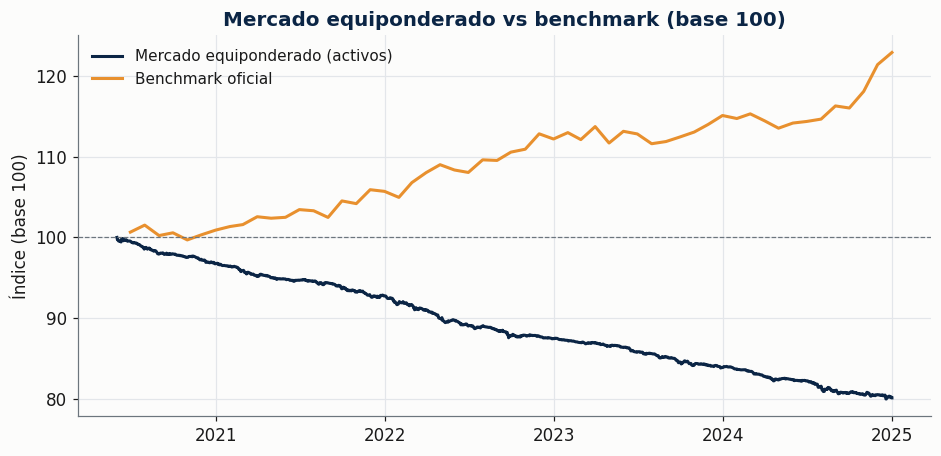

Retorno mercado equiponderado: -19.9%
Retorno benchmark            : 22.9%


In [3]:
market = proc["market"]
bench = proc["benchmark"]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(market.index, market["mkt_index"], color=S.NAVY, label="Mercado equiponderado (activos)")
ax.plot(bench.index, bench["benchmark_index"], color=S.AMBER, label="Benchmark oficial")
ax.axhline(100, color=S.GRAY, lw=0.8, ls="--")
ax.set_title("Mercado equiponderado vs benchmark (base 100)")
ax.set_ylabel("Índice (base 100)")
ax.legend()
plt.show()

print("Retorno mercado equiponderado: "
      f"{(market['mkt_index'].iloc[-1]/market['mkt_index'].iloc[0]-1)*100:.1f}%")
print(f"Retorno benchmark            : {(bench['benchmark_index'].iloc[-1]/100-1)*100:.1f}%")

## Amplitud (fracción de algoritmos en positivo)

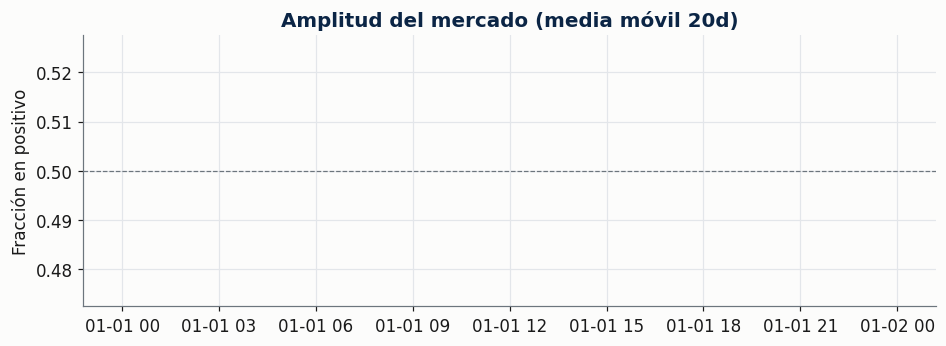

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(market.index, market["breadth"].rolling(20).mean(), color=S.BLUE)
ax.axhline(0.5, color=S.GRAY, lw=0.8, ls="--")
ax.set_title("Amplitud del mercado (media móvil 20d)")
ax.set_ylabel("Fracción en positivo")
plt.show()